## 1. Setup

In [1]:
# Uncomment on a fresh environment (Kaggle / Colab)
!pip install -q openai-whisper librosa noisereduce lightgbm sentence-transformers transformers language-tool-python

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 11.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.2/63.2 kB 3.4 MB/s eta 0:00:00


In [2]:
import os, re, json, glob, math, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa, librosa.display
from tqdm.auto import tqdm
from scipy.stats import pearsonr, spearmanr

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error
import lightgbm as lgb
try:
    from catboost import CatBoostRegressor
    HAS_CATBOOST = True
except ImportError:
    HAS_CATBOOST = False
from sklearn.isotonic import IsotonicRegression
import torch

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

class CFG:
    # ---- paths: point DATA_DIR at the folder holding train.csv / test.csv and the audio folders ----
    DATA_DIR   = "/kaggle/input"          # searched recursively for csv + wav files
    CACHE_DIR  = "./cache"                # transcripts & features are cached here (extraction is the slow part)
    SR         = 16000
    TARGET_DBFS = -20.0                   # loudness normalisation target (RMS)
    TRIM_DB    = 35                       # silence trimming threshold
    DENOISE    = True                     # light spectral-gating denoise for acoustic features
    WAVLM_MODEL   = "microsoft/wavlm-base-plus"
    TEXT_EMB_MODELS = ["sentence-transformers/all-mpnet-base-v2", "BAAI/bge-large-en-v1.5"]
    GEC_MODEL     = "grammarly/coedit-large"   # T5-large grammar corrector
    DEBERTA_MODEL = "microsoft/deberta-v3-base"
    DEBERTA = dict(epochs=6, lr=2e-5, batch_size=8, max_len=320, weight_decay=0.01, warmup=0.1, seeds=[42])
    COLA_MODEL    = "textattack/roberta-base-CoLA"
    LM_MODEL      = "gpt2"
    N_FOLDS = 5
    SEEDS   = [42, 7, 2024]               # repeated CV for stable estimates
    DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"

def seed_everything(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_everything()
os.makedirs(CFG.CACHE_DIR, exist_ok=True)
# Whisper size: large-v3 needs ~10 GB VRAM; fall back gracefully
_vram = torch.cuda.get_device_properties(0).total_memory / 1e9 if torch.cuda.is_available() else 0
CFG.WHISPER_MODEL = "large-v3" if _vram >= 10 else ("medium.en" if _vram > 0 else "small.en")
print("Device:", CFG.DEVICE, f"| VRAM {_vram:.1f} GB | Whisper:", CFG.WHISPER_MODEL)

Device: cuda | VRAM 15.6 GB | Whisper: large-v3


## 2. Load the data

In [3]:
def find_one(pattern):
    hits = sorted(glob.glob(os.path.join(CFG.DATA_DIR, "**", pattern), recursive=True))
    assert hits, f"{pattern} not found under {CFG.DATA_DIR}"
    return hits[0]

train_df = pd.read_csv(find_one("train.csv"))
test_df  = pd.read_csv(find_one("test.csv"))
try:
    sample_sub = pd.read_csv(find_one("sample_submission.csv"))
except AssertionError:
    sample_sub = None

FILE_COL = next(c for c in train_df.columns if "file" in c.lower() or "name" in c.lower())
LABEL_COL = "label" if "label" in train_df.columns else train_df.columns[-1]

# index every wav once: stem -> path, keeping train/test separate if folders say so
all_wavs = glob.glob(os.path.join(CFG.DATA_DIR, "**", "*.wav"), recursive=True)
def build_index(split):
    idx = {}
    for p in all_wavs:
        stem = Path(p).stem
        if split in p.lower() or stem not in idx:   # prefer files inside a folder named after the split
            idx[stem] = p
    return idx
train_idx, test_idx = build_index("train"), build_index("test")

train_df["path"] = train_df[FILE_COL].map(lambda f: train_idx.get(Path(str(f)).stem))
test_df["path"]  = test_df[FILE_COL].map(lambda f: test_idx.get(Path(str(f)).stem))
print("missing train audio:", train_df.path.isna().sum(), "| missing test audio:", test_df.path.isna().sum())
print(train_df.shape, test_df.shape)
train_df.head()

missing train audio: 0 | missing test audio: 0
(769, 3) (216, 3)


,filename,label,path
0,audio_192.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...
1,audio_436.wav,3.0,/kaggle/input/competitions/shl-hiring-assessme...
2,audio_447.wav,3.5,/kaggle/input/competitions/shl-hiring-assessme...
3,audio_126.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...
4,audio_61.wav,2.0,/kaggle/input/competitions/shl-hiring-assessme...


### 2.1 Exploratory analysis

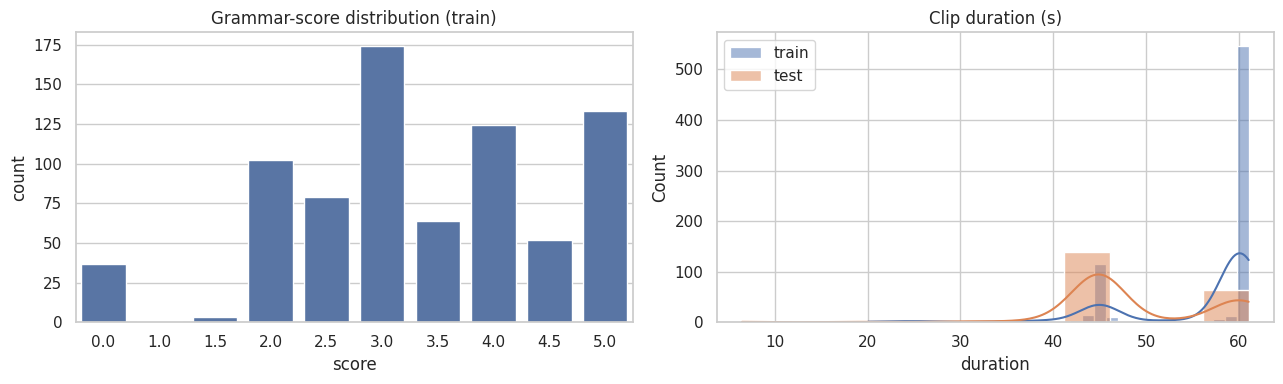

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64


In [4]:
train_df["duration"] = train_df.path.map(lambda p: librosa.get_duration(path=p))
test_df["duration"]  = test_df.path.map(lambda p: librosa.get_duration(path=p))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=train_df[LABEL_COL], ax=ax[0], color="#4C72B0")
ax[0].set_title("Grammar-score distribution (train)"); ax[0].set_xlabel("score")
sns.histplot(train_df.duration, ax=ax[1], label="train", color="#4C72B0", kde=True)
sns.histplot(test_df.duration, ax=ax[1], label="test", color="#DD8452", kde=True)
ax[1].set_title("Clip duration (s)"); ax[1].legend()
plt.tight_layout(); plt.show()
print(train_df[LABEL_COL].describe())

## 3. Audio preprocessing

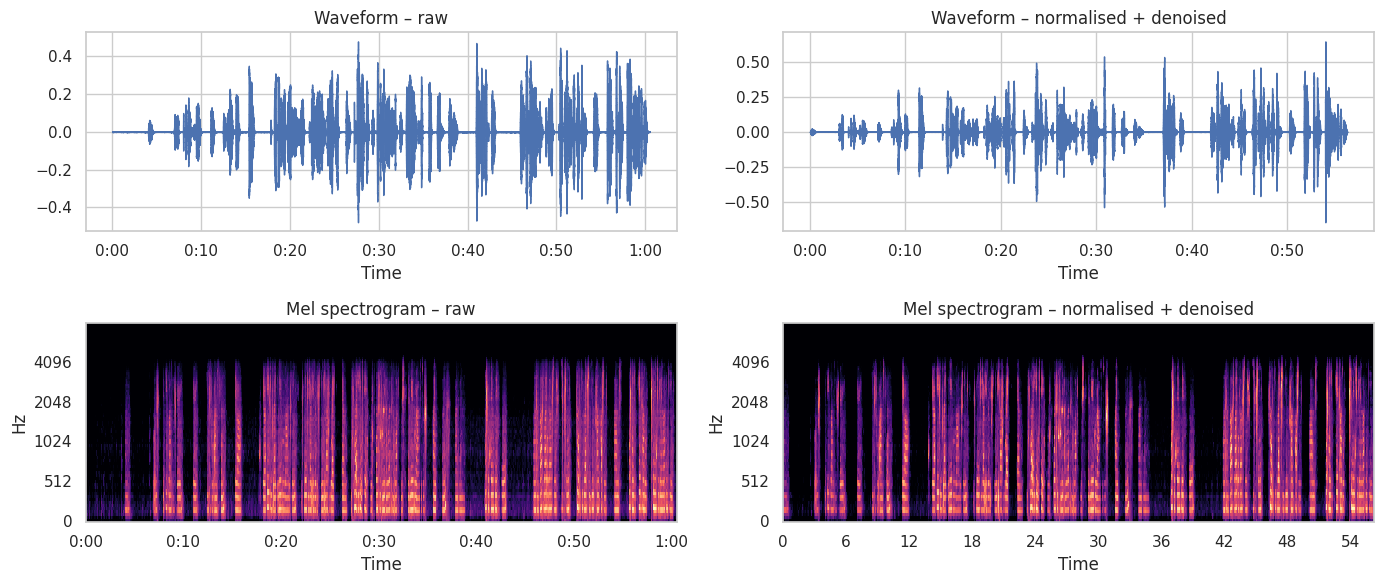

In [5]:
import noisereduce as nr

def load_audio(path, sr=CFG.SR):
    y, _ = librosa.load(path, sr=sr, mono=True)
    return y.astype(np.float32)

def normalise(y, target_dbfs=CFG.TARGET_DBFS, top_db=CFG.TRIM_DB):
    y = y - y.mean()
    y, _ = librosa.effects.trim(y, top_db=top_db)
    rms = np.sqrt(np.mean(y ** 2)) + 1e-9
    y = y * (10 ** (target_dbfs / 20) / rms)
    return np.clip(y, -1.0, 1.0).astype(np.float32)

def denoise(y, sr=CFG.SR):
    return nr.reduce_noise(y=y, sr=sr, stationary=True, prop_decrease=0.8).astype(np.float32)

# visual check on one clip
ex = train_df.path.iloc[0]
raw = load_audio(ex); clean = denoise(normalise(raw))
fig, ax = plt.subplots(2, 2, figsize=(14, 6))
for i, (sig, name) in enumerate([(raw, "raw"), (clean, "normalised + denoised")]):
    librosa.display.waveshow(sig, sr=CFG.SR, ax=ax[0, i]); ax[0, i].set_title(f"Waveform – {name}")
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=sig, sr=CFG.SR, n_mels=80), ref=np.max)
    librosa.display.specshow(S, sr=CFG.SR, x_axis="time", y_axis="mel", ax=ax[1, i]); ax[1, i].set_title(f"Mel spectrogram – {name}")
plt.tight_layout(); plt.show()

## 4. Speech-to-text with Whisper

In [6]:
import whisper

VERBATIM_PROMPT = "Umm, so, uh, I- I was, like, going to the... the market and, hmm, I buyed some, uh, things."

def transcribe_all(df, split):
    cache = Path(CFG.CACHE_DIR) / f"transcripts_{CFG.WHISPER_MODEL}_{split}.json"   # new model -> new cache
    out = json.loads(cache.read_text()) if cache.exists() else {}
    todo = [p for p in df.path if p not in out]
    if todo:
        model = whisper.load_model(CFG.WHISPER_MODEL, device=CFG.DEVICE)
        for p in tqdm(todo, desc=f"Whisper {split}"):
            r = model.transcribe(normalise(load_audio(p)), language="en", temperature=0.0,
                                 initial_prompt=VERBATIM_PROMPT, condition_on_previous_text=False,
                                 word_timestamps=True, fp16=(CFG.DEVICE == "cuda"))
            out[p] = {
                "text": r["text"].strip(),
                "segments": [{"avg_logprob": s["avg_logprob"], "no_speech_prob": s["no_speech_prob"],
                              "compression_ratio": s["compression_ratio"]} for s in r["segments"]],
                "words": [{"w": w["word"], "s": w["start"], "e": w["end"], "p": w["probability"]}
                          for s in r["segments"] for w in s.get("words", [])],
            }
            cache.write_text(json.dumps(out))
        del model; torch.cuda.empty_cache()
    return [out[p] for p in df.path]

train_asr = transcribe_all(train_df, "train")
test_asr  = transcribe_all(test_df, "test")
train_df["text"] = [a["text"] for a in train_asr]
test_df["text"]  = [a["text"] for a in test_asr]

for _, r in train_df.sort_values(LABEL_COL).iloc[[0, len(train_df)//2, -1]].iterrows():
    print(f"[score {r[LABEL_COL]}] {r.text[:300]}...\n")

100%|██████████████████████████████████████| 2.88G/2.88G [00:23<00:00, 133MiB/s]


Whisper train:   0%|          | 0/769 [00:00<?, ?it/s]

Whisper test:   0%|          | 0/216 [00:00<?, ?it/s]

[score 0.0] I'm going to tell you about this thing at the product market. The product market is full of people and selling and buying these vegetables, or vegetables. In the market, you can find vegetables, but people do the both kind of selling and buying. The vegetables will be cost on low or high. But the st...

[score 3.0] The scene of a crowded market is something like- like a very fish market and it is all about selling vegetables on the market and so many people are coming on a particular day where there is more selling of vegetables and on the morning time it will be very crowded in the market that many people wer...

[score 5.0] The journey to Switzerland is an adventure in itself, whether you arrive by plane, train, or car. If you fly into Zurich or Genoa, you'll be greeted by stunning views of the Swiss Alps as you plane descent towards the airport. From there, you can take a scenic train ride to your destination, passing...



## 5. Text (grammar) features

In [7]:
FILLERS = {"um", "umm", "uh", "uhh", "er", "erm", "hmm", "ah", "eh", "mm"}
SUBORD = {"because", "although", "though", "which", "who", "whom", "whose", "that", "when", "while", "whereas",
          "if", "unless", "since", "until", "whether", "where", "after", "before", "so", "therefore", "however"}
# a few classic L2 error patterns (cheap, interpretable heuristics)
ERR_PATTERNS = [r"\b(he|she|it) (don't|have|go|do|want|like|make)\b", r"\b(i|you|we|they) (is|was|has|does|goes)\b",
                r"\b(they|we|you) was\b", r"\b(a) [aeiou]\w+", r"\bmore (better|bigger|easier|good)\b",
                r"\b(is|are|am|was|were) (go|do|make|eat|play|study)\b", r"\b\w+ed\b \b(yesterday|tomorrow)\b"]

def sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text) if len(s.split()) >= 2]

def handcrafted_text_feats(text, asr):
    t = text.lower()
    words = re.findall(r"[a-z']+", t)
    n = max(len(words), 1)
    sents = sentences(text) or [text]
    slen = np.array([len(s.split()) for s in sents])
    reps = sum(words[i] == words[i - 1] for i in range(1, len(words)))
    seg = asr["segments"]; wp = np.array([w["p"] for w in asr["words"]]) if asr["words"] else np.array([np.nan])
    return {
        "n_words": len(words), "n_sent": len(sents), "sent_len_mean": slen.mean(), "sent_len_std": slen.std(),
        "sent_len_max": slen.max(), "ttr": len(set(words)) / n, "word_len": np.mean([len(w) for w in words]) if words else 0,
        "long_word_rate": sum(len(w) >= 7 for w in words) / n,
        "filler_rate": sum(w in FILLERS for w in words) / n, "repeat_rate": reps / n,
        "restart_rate": t.count("-") / n,
        "subord_rate": sum(w in SUBORD for w in words) / n,
        "perfect_rate": len(re.findall(r"\b(have|has|had) \w+(ed|en)\b", t)) / n,
        "modal_rate": len(re.findall(r"\b(would|could|should|might|must|may)\b", t)) / n,
        "passive_rate": len(re.findall(r"\b(is|are|was|were|been|being) \w+(ed|en)\b", t)) / n,
        "ing_rate": sum(w.endswith("ing") for w in words) / n,
        "heur_err_rate": sum(len(re.findall(p, t)) for p in ERR_PATTERNS) / n * 100,
        "asr_logprob": np.mean([s["avg_logprob"] for s in seg]) if seg else np.nan,
        "asr_nospeech": np.mean([s["no_speech_prob"] for s in seg]) if seg else np.nan,
        "asr_compress": np.mean([s["compression_ratio"] for s in seg]) if seg else np.nan,
        "asr_wordprob": np.nanmean(wp), "asr_lowconf": np.nanmean(wp < 0.5),
    }

# ---------- LanguageTool grammar errors (optional: needs Java) ----------
def languagetool_feats(texts):
    try:
        import language_tool_python
        tool = language_tool_python.LanguageTool("en-US")
    except Exception as e:
        print("LanguageTool unavailable -> skipped:", e); return pd.DataFrame(index=range(len(texts)))
    IGNORE = {"TYPOS", "PUNCTUATION", "CASING", "TYPOGRAPHY", "STYLE", "REDUNDANCY", "WHITESPACE"}
    rows = []
    for t in tqdm(texts, desc="LanguageTool"):
        n = max(len(t.split()), 1)
        m = [x for x in tool.check(t) if x.category not in IGNORE]
        cats = pd.Series([x.category for x in m]).value_counts()
        rows.append({"lt_err_per100": len(m) / n * 100,
                     "lt_grammar_per100": cats.get("GRAMMAR", 0) / n * 100,
                     "lt_confused_per100": cats.get("CONFUSED_WORDS", 0) / n * 100,
                     "lt_other_per100": (len(m) - cats.get("GRAMMAR", 0) - cats.get("CONFUSED_WORDS", 0)) / n * 100})
    tool.close()
    return pd.DataFrame(rows)

# ---------- CoLA acceptability ----------
@torch.no_grad()
def cola_feats(texts):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(CFG.COLA_MODEL)
    mdl = AutoModelForSequenceClassification.from_pretrained(CFG.COLA_MODEL).to(CFG.DEVICE).eval()
    rows = []
    for t in tqdm(texts, desc="CoLA"):
        s = sentences(t) or [t]
        enc = tok(s, padding=True, truncation=True, max_length=128, return_tensors="pt").to(CFG.DEVICE)
        p = mdl(**enc).logits.softmax(-1)[:, 1].cpu().numpy()     # label 1 = acceptable
        rows.append({"cola_mean": p.mean(), "cola_min": p.min(), "cola_q25": np.quantile(p, .25),
                     "cola_bad_frac": (p < 0.5).mean()})
    del mdl; torch.cuda.empty_cache()
    return pd.DataFrame(rows)

# ---------- GPT-2 perplexity ----------
@torch.no_grad()
def perplexity_feats(texts):
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(CFG.LM_MODEL)
    mdl = AutoModelForCausalLM.from_pretrained(CFG.LM_MODEL).to(CFG.DEVICE).eval()
    rows = []
    for t in tqdm(texts, desc="GPT-2 PPL"):
        ids = tok(t or ".", return_tensors="pt").input_ids[:, :1024].to(CFG.DEVICE)
        if ids.shape[1] < 2: rows.append({"lm_nll": np.nan, "lm_nll_std": np.nan}); continue
        logits = mdl(ids).logits[0, :-1]
        nll = torch.nn.functional.cross_entropy(logits, ids[0, 1:], reduction="none").cpu().numpy()
        rows.append({"lm_nll": nll.mean(), "lm_nll_std": nll.std(), "lm_nll_p90": np.quantile(nll, .9)})
    del mdl; torch.cuda.empty_cache()
    return pd.DataFrame(rows)

def text_embeddings(texts):
    from sentence_transformers import SentenceTransformer
    embs = []
    for name in CFG.TEXT_EMB_MODELS:                     # MPNet (768-d) + BGE-large (1024-d)
        m = SentenceTransformer(name, device=CFG.DEVICE)
        embs.append(m.encode(texts, batch_size=16, show_progress_bar=True, normalize_embeddings=True))
        del m; torch.cuda.empty_cache()
    return np.hstack(embs)

def cached(name, fn):
    f = Path(CFG.CACHE_DIR) / f"{CFG.WHISPER_MODEL}_{name}"   # every feature depends on the transcripts -> key by ASR model
    if f.exists(): return pd.read_pickle(f)
    out = fn(); pd.to_pickle(out, f); return out

def all_text_features(df, asr, split):
    texts = df.text.fillna("").tolist()
    hand = pd.DataFrame([handcrafted_text_feats(t, a) for t, a in zip(texts, asr)])
    lt   = cached(f"lt_{split}.pkl",   lambda: languagetool_feats(texts))
    cola = cached(f"cola_{split}.pkl", lambda: cola_feats(texts))
    ppl  = cached(f"ppl_{split}.pkl",  lambda: perplexity_feats(texts))
    emb  = cached(f"temb2_{split}.pkl", lambda: text_embeddings(texts))
    return pd.concat([hand, lt, cola, ppl], axis=1), np.asarray(emb)

tr_text, tr_temb = all_text_features(train_df, train_asr, "train")
te_text, te_temb = all_text_features(test_df,  test_asr,  "test")
print(tr_text.shape, tr_temb.shape)

LanguageTool:   0%|          | 0/769 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/14 [00:00<?, ?it/s]

(769, 33) (769, 1792)


## 5.1 Grammatical-error-correction (GEC) features — the biggest new signal

config.json:   0%|          | 0.00/787 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

GEC:   0%|          | 0/266 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/558 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


GEC:   0%|          | 0/71 [00:00<?, ?it/s]

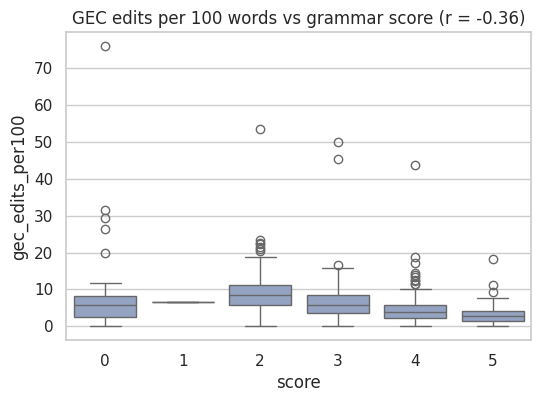

In [8]:
import difflib

def _clean_tokens(s):
    toks = [w for w in re.findall(r"[a-z']+", s.lower()) if w not in FILLERS]
    return [w for i, w in enumerate(toks) if i == 0 or w != toks[i - 1]]   # drop stutter repeats

@torch.no_grad()
def gec_correct(sent_list, bs=16):
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
    tok = AutoTokenizer.from_pretrained(CFG.GEC_MODEL)
    mdl = AutoModelForSeq2SeqLM.from_pretrained(CFG.GEC_MODEL).to(CFG.DEVICE).eval()   # fp32: T5 overflows in fp16
    out = []
    order = np.argsort([len(s) for s in sent_list])                       # length-sorted batching = faster
    res = [None] * len(sent_list)
    for i in tqdm(range(0, len(order), bs), desc="GEC"):
        idx = order[i:i + bs]
        batch = ["Fix grammatical errors in this sentence: " + sent_list[j] for j in idx]
        enc = tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=160).to(CFG.DEVICE)
        gen = mdl.generate(**enc, max_new_tokens=160, num_beams=4)
        for j, txt in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)):
            res[j] = txt
    del mdl; torch.cuda.empty_cache()
    return res

def gec_feats(texts):
    sents = [sentences(t) or [t if t else "."] for t in texts]
    flat = [s for ss in sents for s in ss]
    corr = gec_correct(flat)
    rows, k = [], 0
    for ss in sents:
        sub = ins = dele = changed = n = 0; sims = []
        for s in ss:
            a, b = _clean_tokens(s), _clean_tokens(corr[k]); k += 1
            n += max(len(a), 1)
            for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes():
                if op == "replace": sub += max(i2 - i1, j2 - j1)
                elif op == "delete": dele += i2 - i1
                elif op == "insert": ins += j2 - j1
            changed += a != b
            sims.append(difflib.SequenceMatcher(None, " ".join(a), " ".join(b)).ratio())
        tot = sub + ins + dele
        rows.append({"gec_edits_per100": tot / n * 100, "gec_sub_per100": sub / n * 100,
                     "gec_ins_per100": ins / n * 100, "gec_del_per100": dele / n * 100,
                     "gec_sent_changed": changed / len(ss), "gec_sim_mean": np.mean(sims), "gec_sim_min": np.min(sims)})
    return pd.DataFrame(rows)

tr_gec = cached("gec_train.pkl", lambda: gec_feats(train_df.text.fillna("").tolist()))
te_gec = cached("gec_test.pkl",  lambda: gec_feats(test_df.text.fillna("").tolist()))
tr_text = pd.concat([tr_text, tr_gec], axis=1)
te_text = pd.concat([te_text, te_gec], axis=1)

r = np.corrcoef(tr_gec.gec_edits_per100, train_df[LABEL_COL])[0, 1]
plt.figure(figsize=(6, 4))
sns.boxplot(x=np.round(train_df[LABEL_COL]).astype(int), y=tr_gec.gec_edits_per100, color="#8DA0CB")
plt.title(f"GEC edits per 100 words vs grammar score (r = {r:.2f})"); plt.xlabel("score"); plt.show()

## 6. Speech (fluency & acoustic) features

In [9]:
def fluency_feats(asr, dur):
    w = asr["words"]
    if len(w) < 2:
        return {k: np.nan for k in ["speech_rate", "artic_rate", "pause_per_min", "pause_mean", "pause_max", "phonation_ratio", "long_pause_per_min"]}
    starts, ends = np.array([x["s"] for x in w]), np.array([x["e"] for x in w])
    gaps = starts[1:] - ends[:-1]
    pauses = gaps[gaps > 0.25]
    voiced = np.sum(ends - starts)
    return {"speech_rate": len(w) / dur * 60, "artic_rate": len(w) / max(voiced, 1e-3) * 60,
            "pause_per_min": len(pauses) / dur * 60, "pause_mean": pauses.mean() if len(pauses) else 0,
            "pause_max": pauses.max() if len(pauses) else 0, "phonation_ratio": voiced / dur,
            "long_pause_per_min": (gaps > 1.0).sum() / dur * 60}

def acoustic_feats(y, sr=CFG.SR):
    f0 = librosa.yin(y, fmin=65, fmax=400, sr=sr, frame_length=2048, hop_length=512)
    rms = librosa.feature.rms(y=y, frame_length=2048, hop_length=512)[0]
    n = min(len(f0), len(rms)); f0, rms = f0[:n], rms[:n]
    voiced = f0[rms > np.quantile(rms, 0.3)]   # pitch only where there is speech energy
    st = 12 * np.log2(voiced / np.median(voiced)) if len(voiced) else np.array([np.nan])
    mf = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=20)
    d = {"f0_median": np.median(voiced) if len(voiced) else np.nan, "f0_st_std": np.nanstd(st),
         "f0_st_range": np.nanpercentile(st, 95) - np.nanpercentile(st, 5),
         "rms_cv": rms.std() / (rms.mean() + 1e-9),
         "spec_centroid": librosa.feature.spectral_centroid(y=y, sr=sr).mean(),
         "zcr": librosa.feature.zero_crossing_rate(y).mean()}
    d.update({f"mfcc{i}_mean": v for i, v in enumerate(mf.mean(1))})
    d.update({f"mfcc{i}_std": v for i, v in enumerate(mf.std(1))})
    return d

@torch.no_grad()
def wavlm_embed(paths):
    from transformers import AutoFeatureExtractor, WavLMModel
    fe = AutoFeatureExtractor.from_pretrained(CFG.WAVLM_MODEL)
    mdl = WavLMModel.from_pretrained(CFG.WAVLM_MODEL).to(CFG.DEVICE).eval()
    out = []
    for p in tqdm(paths, desc="WavLM"):
        y = normalise(load_audio(p))
        chunks = [y[i:i + 20 * CFG.SR] for i in range(0, len(y), 20 * CFG.SR) if len(y[i:i + 20 * CFG.SR]) > CFG.SR]
        frames = []
        for c in chunks:                                            # 20 s chunks keep memory bounded
            inp = fe(c, sampling_rate=CFG.SR, return_tensors="pt").input_values.to(CFG.DEVICE)
            hs = mdl(inp, output_hidden_states=True).hidden_states
            frames.append(torch.stack(hs[6:10]).mean(0)[0].cpu())   # (T, 768)
        h = torch.cat(frames).numpy()
        out.append(np.concatenate([h.mean(0), h.std(0)]))
    del mdl; torch.cuda.empty_cache()
    return np.stack(out)

def all_audio_features(df, asr, split):
    def _hand():
        rows = []
        for p, a in tqdm(list(zip(df.path, asr)), desc=f"acoustic {split}"):
            y = normalise(load_audio(p)); dur = len(y) / CFG.SR
            y_dn = denoise(y) if CFG.DENOISE else y
            rows.append({**fluency_feats(a, dur), **acoustic_feats(y_dn), "dur_speech": dur})
        return pd.DataFrame(rows)
    hand = cached(f"acoustic_{split}.pkl", _hand)
    emb  = cached(f"wavlm_{split}.pkl", lambda: wavlm_embed(df.path.tolist()))
    return hand, np.asarray(emb)

tr_ac, tr_aemb = all_audio_features(train_df, train_asr, "train")
te_ac, te_aemb = all_audio_features(test_df,  test_asr,  "test")
print(tr_ac.shape, tr_aemb.shape)

acoustic train:   0%|          | 0/769 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

model.safetensors: downloading bytes:           |  0.00B            

acoustic test:   0%|          | 0/216 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

WavLM:   0%|          | 0/216 [00:00<?, ?it/s]

(769, 54) (769, 1536)


## 7. Feature analysis

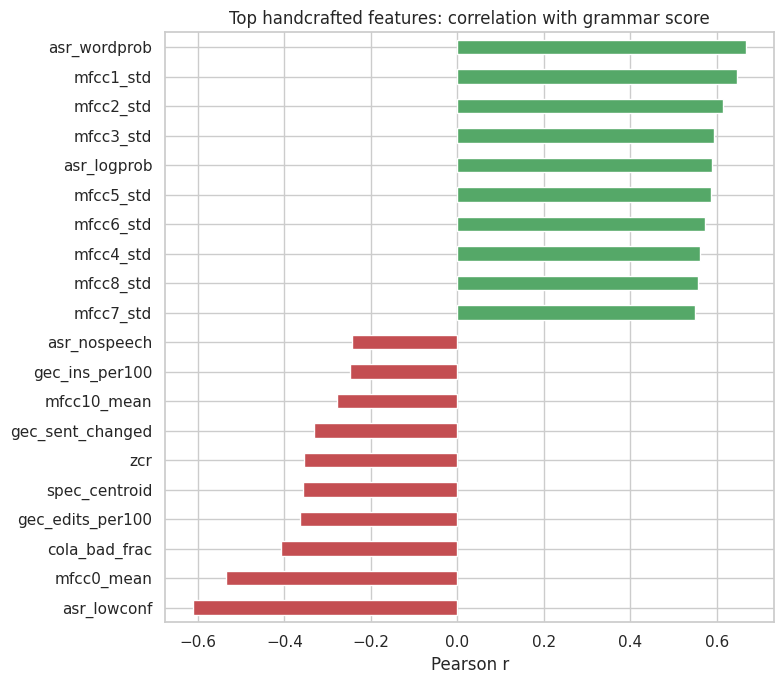

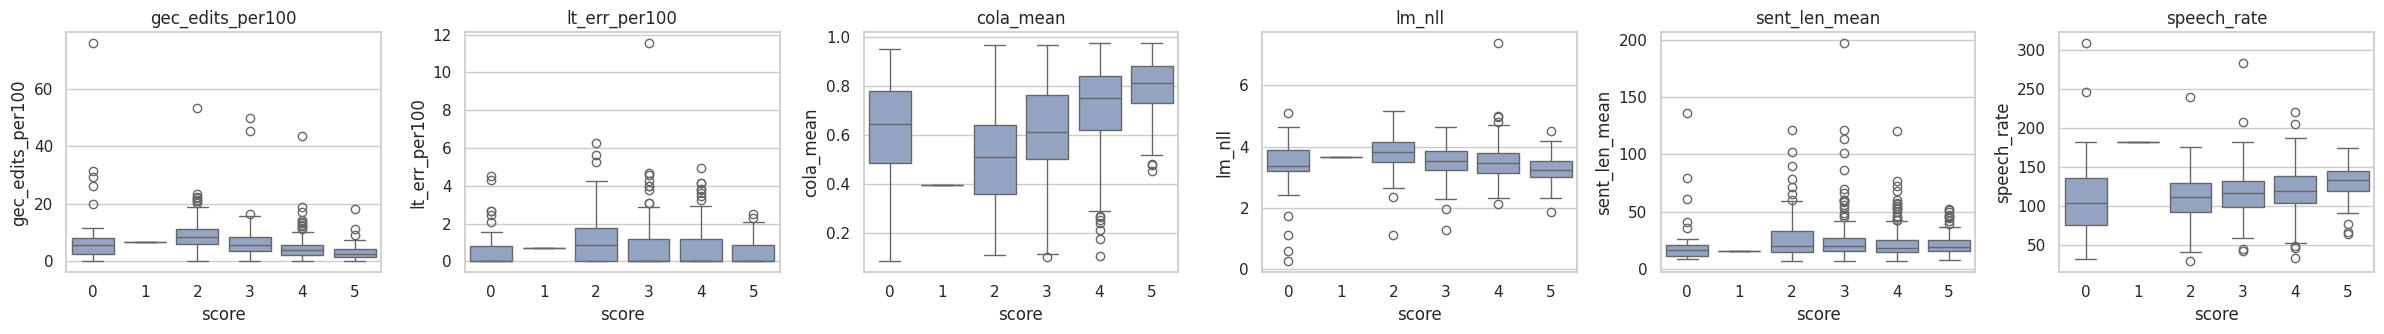

In [10]:
y = train_df[LABEL_COL].values.astype(float)
X_hand_tr = pd.concat([tr_text, tr_ac], axis=1)
X_hand_te = pd.concat([te_text, te_ac], axis=1)[X_hand_tr.columns]

corr = X_hand_tr.apply(lambda c: pd.Series(c.values).corr(pd.Series(y))).dropna().sort_values()
top = pd.concat([corr.head(10), corr.tail(10)])
plt.figure(figsize=(8, 7))
top.plot.barh(color=["#C44E52" if v < 0 else "#55A868" for v in top])
plt.title("Top handcrafted features: correlation with grammar score"); plt.xlabel("Pearson r")
plt.tight_layout(); plt.show()

key = [c for c in ["gec_edits_per100", "lt_err_per100", "cola_mean", "lm_nll", "sent_len_mean", "speech_rate"] if c in X_hand_tr]
fig, axes = plt.subplots(1, len(key), figsize=(4 * len(key), 3.5))
for ax, c in zip(np.atleast_1d(axes), key):
    sns.boxplot(x=np.round(y).astype(int), y=X_hand_tr[c], ax=ax, color="#8DA0CB"); ax.set_title(c); ax.set_xlabel("score")
plt.tight_layout(); plt.show()

## 8. Fine-tuned DeBERTa-v3 regressor on transcripts

In [11]:
y = train_df[LABEL_COL].values.astype(float)
strat = np.clip(np.round(y), 1, 5).astype(int)
FOLDS = {s: list(StratifiedKFold(CFG.N_FOLDS, shuffle=True, random_state=s).split(np.zeros(len(y)), strat))
         for s in CFG.SEEDS}

def metrics(y_true, y_pred):
    return {"RMSE": mean_squared_error(y_true, y_pred) ** 0.5, "MAE": mean_absolute_error(y_true, y_pred),
            "Pearson": pearsonr(y_true, y_pred)[0], "Spearman": spearmanr(y_true, y_pred)[0]}

from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

class TextRegressor(torch.nn.Module):
    def __init__(self, name):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(name).float()
        self.drop = torch.nn.Dropout(0.1)
        self.head = torch.nn.Linear(self.backbone.config.hidden_size, 1)
    def forward(self, input_ids, attention_mask):
        h = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).float()
        pooled = (h * m).sum(1) / m.sum(1).clamp(min=1)            # mean pooling
        return self.head(self.drop(pooled)).squeeze(-1)

def _loader(tok, texts, targets=None, shuffle=False):
    enc = tok(texts, truncation=True, max_length=CFG.DEBERTA["max_len"])
    items = [{"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i],
              "y": (targets[i] if targets is not None else 0.0)} for i in range(len(texts))]
    def collate(b):
        L = max(len(x["input_ids"]) for x in b)
        ids = torch.tensor([x["input_ids"] + [tok.pad_token_id] * (L - len(x["input_ids"])) for x in b])
        am = torch.tensor([x["attention_mask"] + [0] * (L - len(x["attention_mask"])) for x in b])
        return ids, am, torch.tensor([x["y"] for x in b], dtype=torch.float)
    return DataLoader(items, batch_size=CFG.DEBERTA["batch_size"], shuffle=shuffle, collate_fn=collate)

@torch.no_grad()
def _predict(model, dl):
    model.eval(); out = []
    for ids, am, _ in dl:
        with torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
            out.append(model(ids.to(CFG.DEVICE), am.to(CFG.DEVICE)).float().cpu())
    return torch.cat(out).numpy()

def train_deberta(tr_texts, y_tr, pred_sets, seed):
    seed_everything(seed)
    p = CFG.DEBERTA
    tok = AutoTokenizer.from_pretrained(CFG.DEBERTA_MODEL)
    model = TextRegressor(CFG.DEBERTA_MODEL).to(CFG.DEVICE)
    model.head.bias.data.fill_(float(np.mean(y_tr)))               # start at the mean score
    dl = _loader(tok, tr_texts, y_tr, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
    steps = len(dl) * p["epochs"]
    sch = get_linear_schedule_with_warmup(opt, int(p["warmup"] * steps), steps)
    scaler = torch.cuda.amp.GradScaler(enabled=CFG.DEVICE == "cuda")
    for ep in range(p["epochs"]):
        model.train()
        for ids, am, t in dl:
            with torch.autocast("cuda", enabled=CFG.DEVICE == "cuda"):
                loss = torch.nn.functional.mse_loss(model(ids.to(CFG.DEVICE), am.to(CFG.DEVICE)).float(), t.to(CFG.DEVICE))
            opt.zero_grad(); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
    preds = [_predict(model, _loader(tok, s)) for s in pred_sets]
    del model; torch.cuda.empty_cache()
    return preds

def deberta_cv():
    tr_t, te_t = train_df.text.fillna("").tolist(), test_df.text.fillna("").tolist()
    oof_d, test_d, train_d = np.zeros(len(y)), np.zeros(len(te_t)), np.zeros(len(y))
    seeds = CFG.DEBERTA["seeds"]; k = len(seeds) * CFG.N_FOLDS
    for s in seeds:
        for f, (tr_i, va_i) in enumerate(FOLDS[CFG.SEEDS[0]]):
            va_p, te_p, all_p = train_deberta([tr_t[i] for i in tr_i], y[tr_i],
                                              [[tr_t[i] for i in va_i], te_t, tr_t], seed=s + f)
            oof_d[va_i] += va_p / len(seeds); test_d += te_p / k; train_d += all_p / k
            print(f"seed {s} fold {f}: RMSE {mean_squared_error(y[va_i], va_p) ** 0.5:.4f}")
    return {"oof": oof_d, "test": test_d, "train": train_d}

deb = cached(f"deberta_{CFG.DEBERTA_MODEL.split('/')[-1]}.pkl", deberta_cv)
print("DeBERTa OOF:", {k: round(v, 4) for k, v in metrics(y, np.clip(deb["oof"], 0, 5)).items()})

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


seed 42 fold 3: RMSE 0.8879


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
mask_predictions.classifier.weight      | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


seed 42 fold 4: RMSE 0.7646
DeBERTa OOF: {'RMSE': 0.8463, 'MAE': 0.5871, 'Pearson': np.float64(0.7383), 'Spearman': np.float64(0.7802)}


## 9. Classical base models + stacking

In [12]:
X_hand_tr = pd.concat([tr_text, tr_ac], axis=1)                    # rebuild with GEC features
X_hand_te = pd.concat([te_text, te_ac], axis=1)[X_hand_tr.columns]
text_cols = tr_text.columns

blocks_tr = {"ridge_text":  np.hstack([tr_temb, tr_text.values]), "ridge_audio": tr_aemb,
             "lgbm_hand": X_hand_tr.values, "svr_hand": X_hand_tr.values}
blocks_te = {"ridge_text":  np.hstack([te_temb, te_text[text_cols].values]), "ridge_audio": te_aemb,
             "lgbm_hand": X_hand_te.values, "svr_hand": X_hand_te.values}
if HAS_CATBOOST:
    blocks_tr["cat_hand"], blocks_te["cat_hand"] = X_hand_tr.values, X_hand_te.values

def make_model(name):
    if name in ("ridge_text", "ridge_audio"):
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-1, 5, 40)))
    if name == "lgbm_hand":
        return lgb.LGBMRegressor(n_estimators=700, learning_rate=0.02, num_leaves=12, min_child_samples=20,
                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=3.0, verbose=-1)
    if name == "cat_hand":
        return CatBoostRegressor(iterations=1500, learning_rate=0.03, depth=5, l2_leaf_reg=5, loss_function="RMSE",
                                 random_seed=0, verbose=0)
    if name == "svr_hand":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=2.0, epsilon=0.15, gamma="scale"))

oof = {m: np.zeros(len(y)) for m in blocks_tr}
for seed in CFG.SEEDS:
    for tr_i, va_i in tqdm(FOLDS[seed], desc=f"CV seed {seed}"):
        for m, X in blocks_tr.items():
            oof[m][va_i] += make_model(m).fit(X[tr_i], y[tr_i]).predict(X[va_i]) / len(CFG.SEEDS)
oof["deberta"] = deb["oof"]
MODEL_NAMES = list(oof)

# ---- stacking (cross-validated) ----
O = np.column_stack([oof[m] for m in MODEL_NAMES])
stack_lin, stack_iso = np.zeros(len(y)), np.zeros(len(y))
for tr_i, va_i in StratifiedKFold(CFG.N_FOLDS, shuffle=True, random_state=0).split(O, strat):
    st = LinearRegression(positive=True).fit(O[tr_i], y[tr_i])
    stack_lin[va_i] = st.predict(O[va_i])
    iso = IsotonicRegression(y_min=0, y_max=5, out_of_bounds="clip").fit(st.predict(O[tr_i]), y[tr_i])
    stack_iso[va_i] = 0.5 * stack_lin[va_i] + 0.5 * iso.predict(stack_lin[va_i])   # half-blend: smoother than pure isotonic
stack_lin, stack_iso = np.clip(stack_lin, 0, 5), np.clip(stack_iso, 0, 5)
USE_ISO = metrics(y, stack_iso)["RMSE"] < metrics(y, stack_lin)["RMSE"]
stack_oof = stack_iso if USE_ISO else stack_lin

stacker = LinearRegression(positive=True).fit(O, y)
iso_full = IsotonicRegression(y_min=0, y_max=5, out_of_bounds="clip").fit(stacker.predict(O), y)
def final_transform(base_preds):
    p = stacker.predict(base_preds)
    if USE_ISO: p = 0.5 * p + 0.5 * iso_full.predict(p)
    return np.clip(p, 0, 5)

cv_table = pd.DataFrame({m: metrics(y, np.clip(p, 0, 5)) for m, p in oof.items()} |
                        {"STACK (linear)": metrics(y, stack_lin), "STACK + isotonic": metrics(y, stack_iso)}).T
print("Stacker weights:", dict(zip(MODEL_NAMES, stacker.coef_.round(3))), "| intercept", round(stacker.intercept_, 3))
print("Isotonic calibration used:", USE_ISO)
cv_table.style.format("{:.4f}").highlight_min("RMSE").highlight_max("Pearson")

CV seed 42:   0%|          | 0/5 [00:00<?, ?it/s]

CV seed 7:   0%|          | 0/5 [00:00<?, ?it/s]

CV seed 2024:   0%|          | 0/5 [00:00<?, ?it/s]

Stacker weights: {'ridge_text': np.float64(0.053), 'ridge_audio': np.float64(0.602), 'lgbm_hand': np.float64(0.078), 'svr_hand': np.float64(0.146), 'cat_hand': np.float64(0.101), 'deberta': np.float64(0.161)} | intercept -0.481
Isotonic calibration used: True


,RMSE,MAE,Pearson,Spearman
ridge_text,0.8257,0.6279,0.7460,0.7588
ridge_audio,0.5478,0.4124,0.8972,0.8511
lgbm_hand,0.6212,0.4782,0.8654,0.8082
svr_hand,0.6539,0.4980,0.8505,0.8106
cat_hand,0.6159,0.4794,0.8685,0.8137
deberta,0.8463,0.5871,0.7383,0.7802
STACK (linear),0.4935,0.3724,0.9175,0.8822
STACK + isotonic,0.4915,0.3656,0.9179,0.8786


## 10. Final training & **training RMSE**

In [13]:
full_models = {m: make_model(m).fit(X, y) for m, X in blocks_tr.items()}
def base_matrix(blocks, deb_pred):
    cols = {m: full_models[m].predict(blocks[m]) for m in blocks}
    cols["deberta"] = deb_pred
    return np.column_stack([cols[m] for m in MODEL_NAMES])

train_pred = final_transform(base_matrix(blocks_tr, deb["train"]))
test_pred  = final_transform(base_matrix(blocks_te, deb["test"]))

train_m = metrics(y, train_pred)
cv_m = pd.Series(metrics(y, stack_oof))
print("=" * 55)
print(f"  TRAINING RMSE (in-sample)      : {train_m['RMSE']:.4f}")
print(f"  Training Pearson r             : {train_m['Pearson']:.4f}")
print(f"  CV RMSE (out-of-fold)          : {cv_m['RMSE']:.4f}")
print(f"  CV Pearson r (out-of-fold)     : {cv_m['Pearson']:.4f}")
print("=" * 55)

  TRAINING RMSE (in-sample)      : 0.2174
  Training Pearson r             : 0.9845
  CV RMSE (out-of-fold)          : 0.4915
  CV Pearson r (out-of-fold)     : 0.9179


## 11. Evaluation visualisations

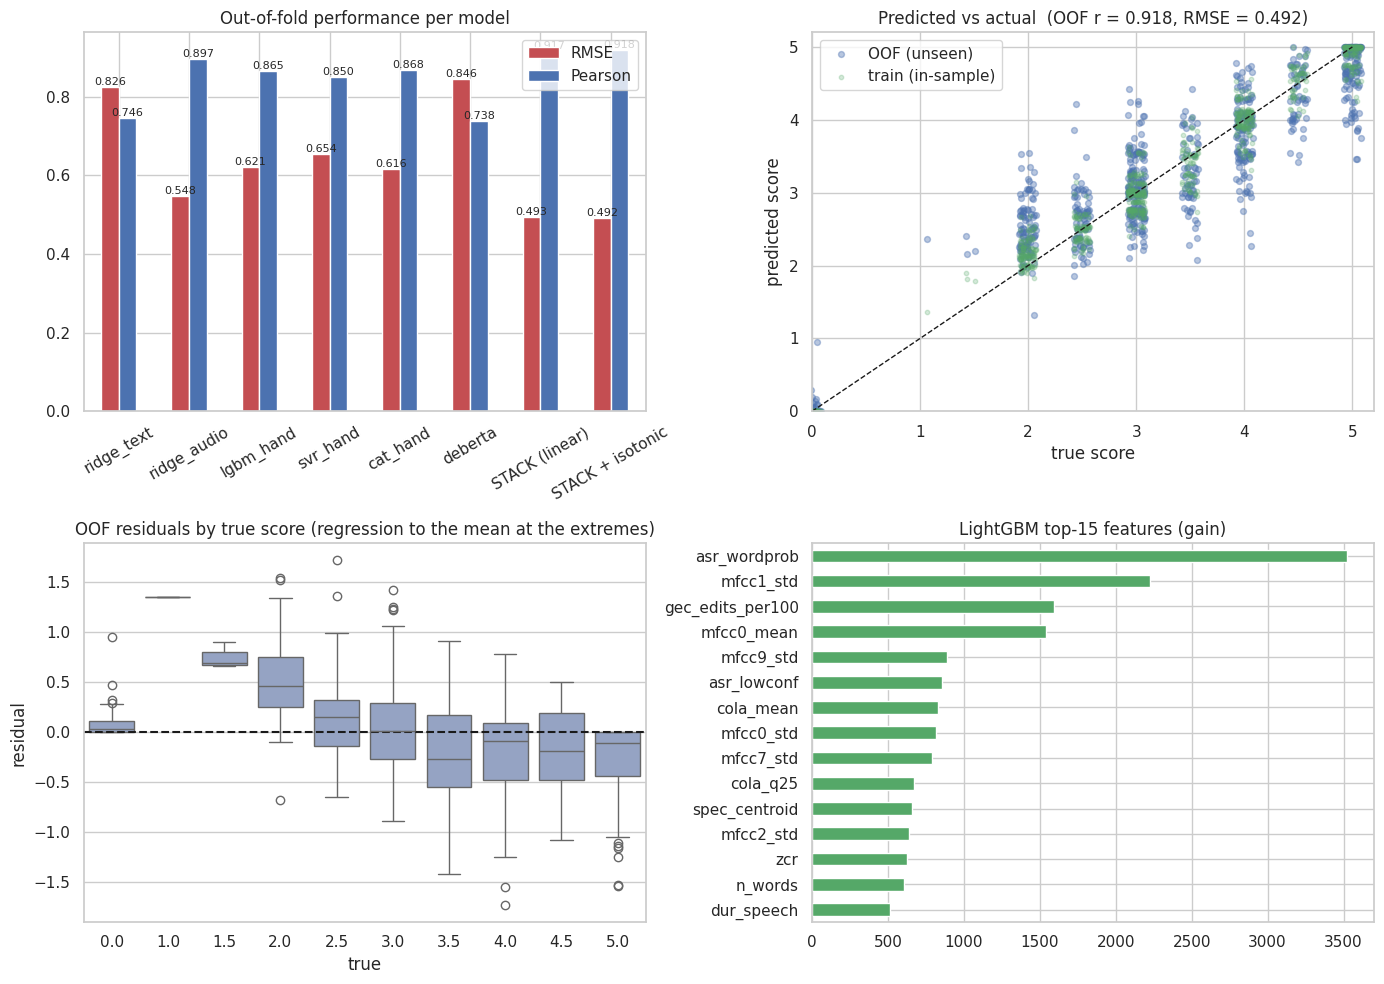

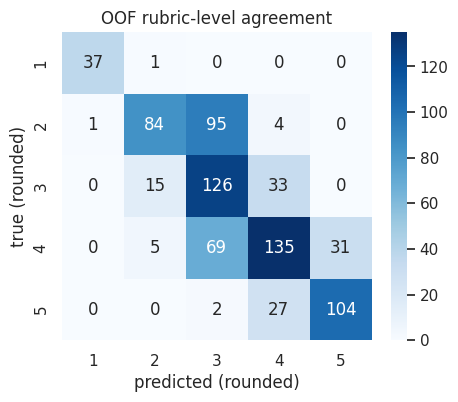

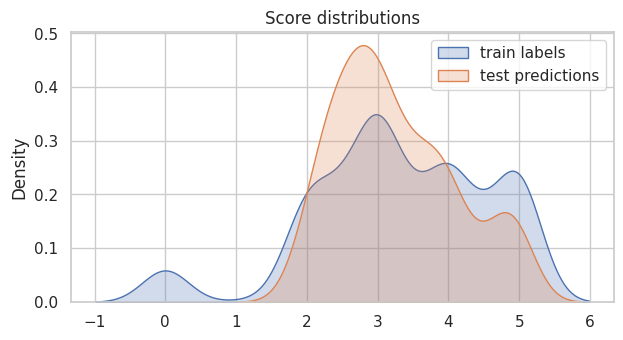

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (a) model comparison
cv_table[["RMSE", "Pearson"]].plot.bar(ax=ax[0, 0], color=["#C44E52", "#4C72B0"], rot=30)
ax[0, 0].set_title("Out-of-fold performance per model"); ax[0, 0].bar_label(ax[0, 0].containers[0], fmt="%.3f", fontsize=8)
ax[0, 0].bar_label(ax[0, 0].containers[1], fmt="%.3f", fontsize=8)

# (b) predicted vs actual (OOF)
jit = y + np.random.uniform(-0.08, 0.08, len(y))
ax[0, 1].scatter(jit, stack_oof, alpha=0.4, s=18, label="OOF (unseen)")
ax[0, 1].scatter(jit, train_pred, alpha=0.25, s=10, c="#55A868", label="train (in-sample)")
ax[0, 1].plot([0, 5], [0, 5], "k--", lw=1); ax[0, 1].set_xlim(0, 5.2); ax[0, 1].set_ylim(0, 5.2)
ax[0, 1].set_xlabel("true score"); ax[0, 1].set_ylabel("predicted score"); ax[0, 1].legend()
ax[0, 1].set_title(f"Predicted vs actual  (OOF r = {cv_m['Pearson']:.3f}, RMSE = {cv_m['RMSE']:.3f})")

# (c) residuals per true score
res = pd.DataFrame({"true": y, "residual": stack_oof - y})
sns.boxplot(data=res, x="true", y="residual", ax=ax[1, 0], color="#8DA0CB"); ax[1, 0].axhline(0, c="k", ls="--")
ax[1, 0].set_title("OOF residuals by true score (regression to the mean at the extremes)")

# (d) LightGBM feature importance (gain)
imp = pd.Series(full_models["lgbm_hand"].booster_.feature_importance("gain"), index=X_hand_tr.columns).nlargest(15)
imp[::-1].plot.barh(ax=ax[1, 1], color="#55A868"); ax[1, 1].set_title("LightGBM top-15 features (gain)")
plt.tight_layout(); plt.show()

# (e) rounded-score confusion matrix, an intuitive view for the rubric levels
from sklearn.metrics import confusion_matrix
lv = [1, 2, 3, 4, 5]
cm = confusion_matrix(np.clip(np.round(y), 1, 5), np.clip(np.round(stack_oof), 1, 5), labels=lv)
plt.figure(figsize=(5, 4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=lv, yticklabels=lv)
plt.xlabel("predicted (rounded)"); plt.ylabel("true (rounded)"); plt.title("OOF rubric-level agreement"); plt.show()

# (f) test prediction distribution vs train labels
plt.figure(figsize=(7, 3.5))
sns.kdeplot(y, label="train labels", fill=True); sns.kdeplot(test_pred, label="test predictions", fill=True)
plt.legend(); plt.title("Score distributions"); plt.show()

## 12. Submission file

In [15]:
sub_cols = list(sample_sub.columns) if sample_sub is not None else [FILE_COL, "label"]
submission = pd.DataFrame({sub_cols[0]: test_df[FILE_COL].values, sub_cols[1]: test_pred})
submission.to_csv("submission.csv", index=False)
print(submission.shape); submission.head()

(216, 2)


,filename,label
0,audio_128.wav,2.753033
1,audio_156.wav,4.056706
2,audio_19.wav,4.742086
3,audio_108.wav,1.911134
4,audio_206.wav,2.196382
